In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate a synthetic time-series trend with seasonality and noise
np.random.seed(42)
dates = pd.date_range(start="2025-01-01", periods=365, freq="D")
trend = np.linspace(50, 150, 365)
seasonality = 20 * np.sin(np.linspace(0, 3 * np.pi, 365))
noise = np.random.normal(0, 5, 365)
sales = trend + seasonality + noise

# Create a dataframe
ts_df = pd.DataFrame({"date": dates, "sales": sales})
ts_df.set_index("date", inplace=True)

# 2. Create Lag Features (e.g., using sales from 1 day ago and 7 days ago to predict today)
ts_df["lag_1"] = ts_df["sales"].shift(1)
ts_df["lag_7"] = ts_df["sales"].shift(7)

# Drop rows with NaN values created by shifting
ts_df = ts_df.dropna()

# 3. Separate Features (X) and Target (y)
X = ts_df[["lag_1", "lag_7"]]
y = ts_df["sales"]

# 4. Chronological Train-Test Split (NO random shuffling!)
train_size = int(len(ts_df) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print("Time-series training shape:", X_train.shape)
print("Time-series testing shape:", X_test.shape)

Time-series training shape: (286, 2)
Time-series testing shape: (72, 2)


--- Time Series Autoregression Metrics ---
TS MAE  : 3.6897
TS RMSE : 4.5254
TS R²   : -0.2347


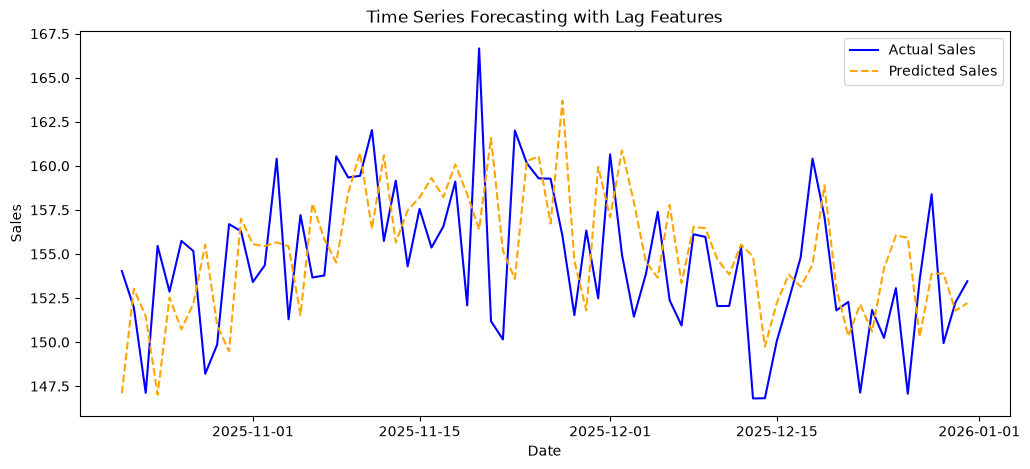

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# 1. Initialize and train the Linear Regressor on chronological time-series data
ts_model = LinearRegression()
ts_model.fit(X_train, y_train)

# 2. Predict on the future test set
y_pred_ts = ts_model.predict(X_test)

# 3. Evaluate performance
print("--- Time Series Autoregression Metrics ---")
print(f"TS MAE  : {mean_absolute_error(y_test, y_pred_ts):.4f}")
print(f"TS RMSE : {root_mean_squared_error(y_test, y_pred_ts):.4f}")
print(f"TS R²   : {r2_score(y_test, y_pred_ts):.4f}")

# 4. Optional: Plot actual vs predicted sales over time
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual Sales", color="blue")
plt.plot(y_test.index, y_pred_ts, label="Predicted Sales", color="orange", linestyle="--")
plt.title("Time Series Forecasting with Lag Features")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()